# Are the coded-aperture positions right?

In [1]:
# Paths (hardcoded: this notebook does not read config_steps15.conf)
PATH_H5    = '/data3/cekmekci/AtomiumS2_coded/ht/codedHT.h5'
PATH_H5_CA = '/data3/cekmekci/AtomiumS2_coded/nfp/data_nfp.h5'
PATH_CODE  = '/data3/cekmekci/AtomiumS2_coded/nfp/code.npy'
PATH_PRB   = '/data3/cekmekci/AtomiumS2_coded/nfp/prb.npy'
OUT_DIR    = '/data3/cekmekci/AtomiumS2_coded/ht'

In [2]:
import numpy as np
import cupy as cp
import h5py
import matplotlib.pyplot as plt
from holotomocupy.propagation import Propagation

# --- display: never let matplotlib resample an array ------------------------------------------
# imshow DOWNSAMPLES to the axes size by default and smooths while doing it, which erases 1-2 px
# structure before it ever reaches the screen. resample=False + nearest makes whatever shrinking
# still happens pixel-picking rather than blurring, and the higher dpi gives the axes enough
# device pixels to be worth looking at. Applies to every imshow below -- none of them override it.
import matplotlib as mpl
mpl.rcParams['image.interpolation'] = 'none'
mpl.rcParams['image.resample']      = False
mpl.rcParams['figure.dpi']          = 150
mpl.rcParams['savefig.dpi']         = 150


def show1to1(img, y0=None, x0=None, size=512, title=None, **kw):
    """Display a patch at EXACTLY one array element per screen pixel.

    A 2048^2 array cannot be shown honestly in a 3-panel row at any dpi -- there are not enough
    device pixels. This is the only way to actually see fine structure: take a `size`-px window
    and give it a `size`-px axes that fills the whole figure, so nothing is scaled at all.
    """
    a = np.asarray(img)
    y0 = a.shape[0] // 2 - size // 2 if y0 is None else int(y0)
    x0 = a.shape[1] // 2 - size // 2 if x0 is None else int(x0)
    sub = a[y0:y0 + size, x0:x0 + size]
    fig = plt.figure(figsize=(sub.shape[1] / 100, sub.shape[0] / 100), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_axis_off()
    ax.imshow(sub, interpolation='nearest', resample=False, **kw)
    if title: ax.set_title(title, fontsize=9, color='k', loc='left')
    plt.show()
    return sub

with h5py.File(PATH_H5, 'r') as f:
    energy = float(f['/exchange/energy'][0])
    det_px = float(f['/exchange/detector_pixelsize'][0])
    fdd    = float(f['/exchange/focusdetectordistance'][0])
    z1     = float(f['/exchange/z1'][0])
    nz, n  = f['/exchange/pdata'].shape[1:]
    pref0  = f['/exchange/pref0'][:].astype('float32')
with h5py.File(PATH_H5_CA, 'r') as f:
    z1_code = float(f['/exchange/z1'][0])

wavelength = 1.24e-9 / energy
distance   = z1 * (fdd - z1) / fdd
voxelsize  = det_px / (fdd / z1)
z2c        = z1 - z1_code
norm_mag   = (z1 / z1_code) / (z1_code / z1)
distance_code = (z1_code * z2c) / (z1_code + z2c) * norm_mag**2 * (z1_code / z1)**2

code  = cp.asarray(np.load(PATH_CODE).astype('complex64'))
prb   = cp.asarray(np.load(PATH_PRB).astype('complex64'))
ncode = code.shape[0]
D     = Propagation(n, nz, 1, 1, wavelength, voxelsize, [distance])
Dcode = Propagation(n, nz, 1, 1, wavelength, voxelsize, [distance_code])

print(f'pref0 {pref0.shape}  code {ncode}^2  detector {nz}x{n}')
print(f'distance {distance*1e3:.4f} mm   distance_code {distance_code*1e3:.4f} mm   '
      f'voxelsize {voxelsize*1e9:.3f} nm')

pref0 (2048, 2048)  code 8192^2  detector 2048x2048
distance 2.9432 mm   distance_code -3.4403 mm   voxelsize 7.001 nm


/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


In [3]:
# Where does the code sit in pref0? Same recipe as step3: divide the probe envelope out,
# pad to the code plane, correlate against the probe-free propagated code, take the argmax.
ref = cp.abs(D.D(Dcode.D(prb, 0), 0)) ** 2                   # probe only, detector size
P8  = Propagation(ncode, ncode, 1, 1, wavelength, voxelsize, [distance])
P8c = Propagation(ncode, ncode, 1, 1, wavelength, voxelsize, [distance_code])
cdata = cp.abs(P8.D(P8c.D(code, 0), 0)) ** 2                 # code only, 8192^2
del P8, P8c
cp.get_default_memory_pool().free_all_blocks()

pad = (ncode - n) // 2
rpad = cp.pad(cp.asarray(pref0) / (ref + 1e-6), ((pad, pad), (pad, pad)), constant_values=1)
cc = cp.fft.fftshift(cp.fft.ifft2(cp.fft.fft2(cdata) * cp.conj(cp.fft.fft2(rpad))).real)
iy, ix = (int(v.get()) for v in cp.unravel_index(cp.argmax(cc), cc.shape))
sy, sx = -(iy - ncode // 2), -(ix - ncode // 2)
del cc, rpad, cdata
cp.get_default_memory_pool().free_all_blocks()
print(f'pref0 code shift: ({sy}, {sx})')

pref0 code shift: (-133, 235)


RMS |ratio - 1| = 0.0856   (0 = perfect)


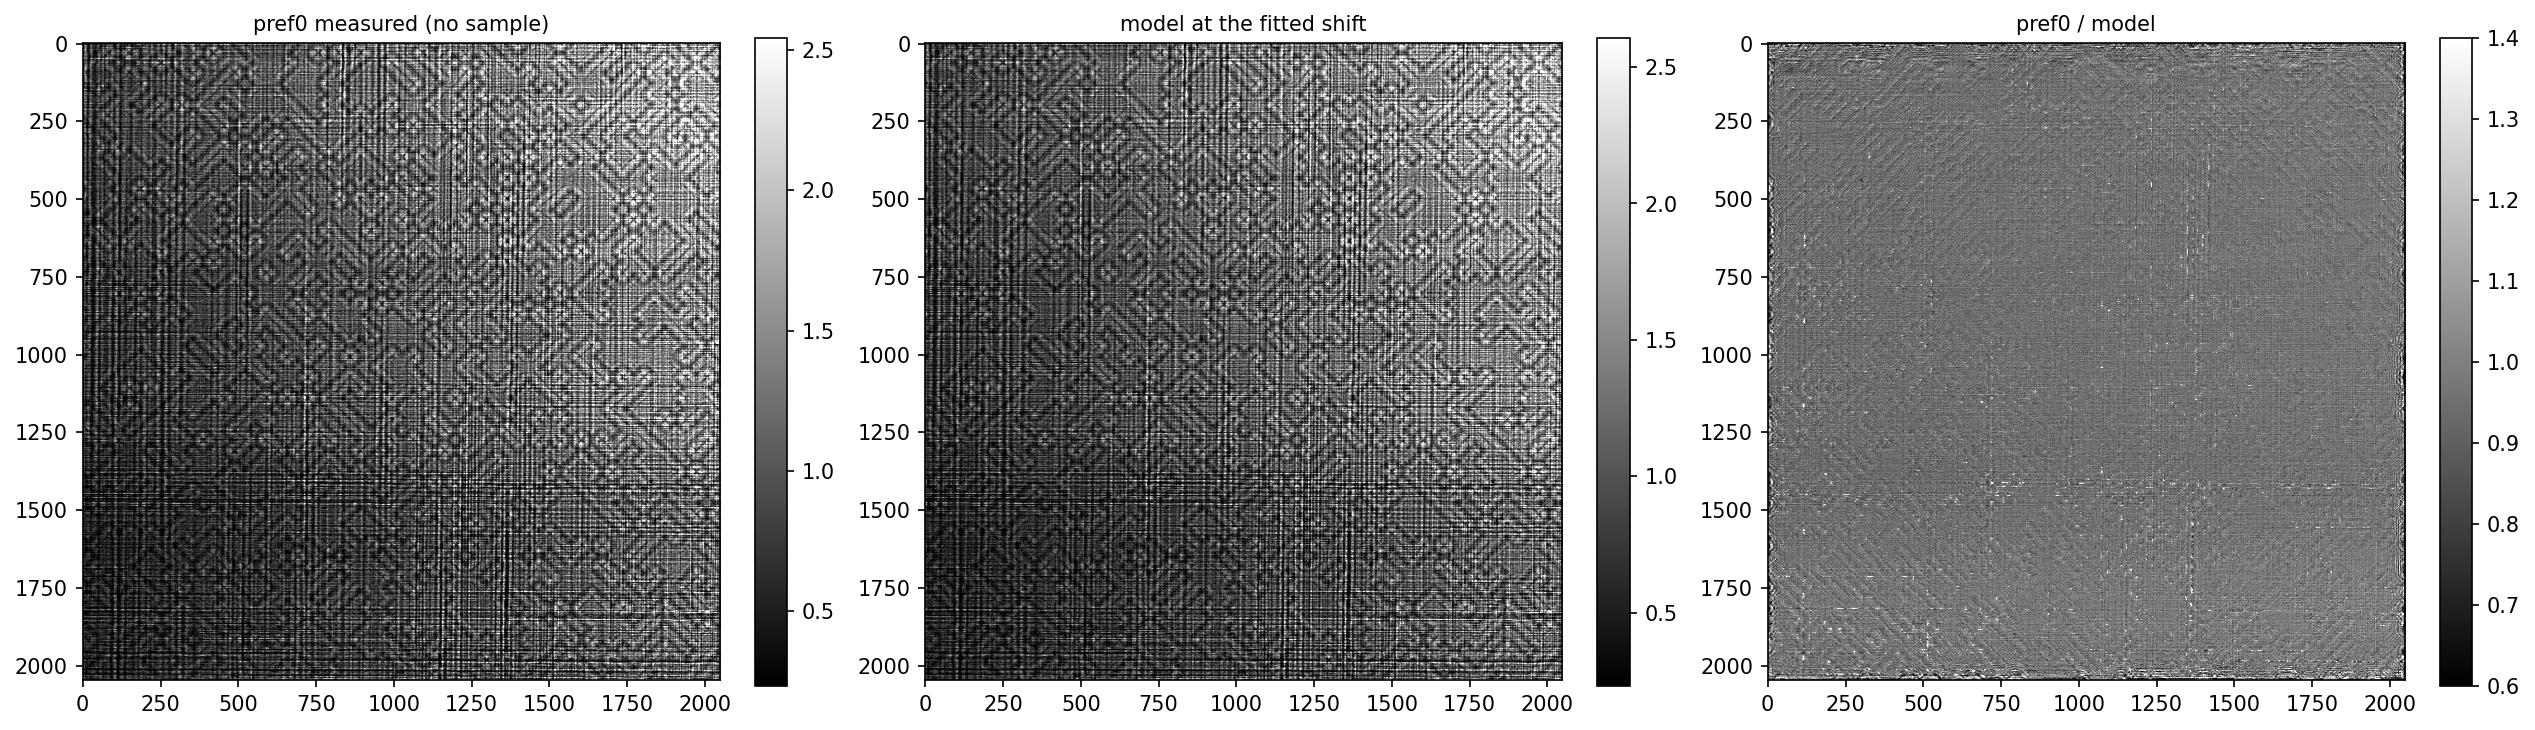

In [4]:
# Model at that shift, then divide. Perfect model -> ratio is 1 everywhere.
cr, cx = ncode // 2 - sy, ncode // 2 - sx
w = code[cr - nz // 2: cr + nz // 2, cx - n // 2: cx + n // 2]
model = cp.abs(D.D(Dcode.D(prb * w, 0), 0)) ** 2

CROP = 0                                                   # ignore the known-bad modelled rim
sl = (slice(CROP, nz - CROP), slice(CROP, n - CROP))
ratio = cp.asnumpy(cp.asarray(pref0) / (model + 1e-6))
# ratio /= np.median(ratio[sl])                                # only the SHAPE matters, not the scale
print(f'RMS |ratio - 1| = {np.sqrt(((ratio[sl] - 1) ** 2).mean()):.4f}   (0 = perfect)')

fig, ax = plt.subplots(1, 3, figsize=(17, 5.4))
for a, img, t, kw in (
        (ax[0], pref0[sl], 'pref0 measured (no sample)', {}),
        (ax[1], cp.asnumpy(model)[sl], 'model at the fitted shift', {}),
        (ax[2], ratio[sl], 'pref0 / model', dict(cmap='gray', vmin=0.6, vmax=1.4))):
    if not kw:
        lo, hi = np.percentile(img, [1, 99])
        kw = dict(cmap='gray', vmin=lo, vmax=hi)
    im = a.imshow(img, **kw); a.set_title(t, fontsize=10)
    fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

In [5]:
# --- manual sub-pixel alignment -----------------------------------------------------------------
# Arrow buttons nudge the code off the fitted integer shift; z1_code retunes the code->sample
# distance; the window sliders choose which patch to inspect. Overview shows where the window is.
# At full 2048 the code speckle is too fine to judge an alignment by eye, hence the zoom.
import ipywidgets as W
import cupyx.scipy.ndimage as cndi
from IPython.display import display
from matplotlib.patches import Rectangle

CROP = 128                                     # unreliable modelled rim, excluded from the metric
sl = (slice(CROP, nz - CROP), slice(CROP, n - CROP))
G = 8


def fshift(arr, dc, dr):
    """Sub-pixel Fourier shift of a complex array."""
    nr, nc = arr.shape
    fr = cp.fft.fftfreq(nr).astype('float32')
    fc = cp.fft.fftfreq(nc).astype('float32')
    Fc, Fr = cp.meshgrid(fc, fr)
    return cp.fft.ifft2(cp.fft.fft2(arr.astype('complex64'))
                        * cp.exp(-2j * cp.pi * (Fr * dr + Fc * dc)).astype('complex64'))


def set_distance(prop, dist):
    """Retune a Propagation in place. Only fker_x / fker_y depend on the distance -- the
    pre-allocated buffer and the cuFFT plan do not -- so this is microseconds, not a rebuild.
    Mirrors the constructor's own expressions exactly (propagation.py:30-40); verified to give
    bit-identical kernels and bit-identical D() output against a freshly built Propagation."""
    fx = cp.fft.fftfreq(2 * prop.n, d=prop.voxelsize)
    fy = cp.fft.fftfreq(2 * prop.nz, d=prop.voxelsize)
    z = cp.asarray([dist])[:, None]
    prop.fker_x = (cp.exp(-1j * cp.pi * prop.wavelength * z * fx[None, :] ** 2)
                   / float(4 * prop.n * prop.nz)).astype('complex64')
    prop.fker_y = cp.exp(-1j * cp.pi * prop.wavelength * z * fy[None, :] ** 2).astype('complex64')
    prop.distance = [dist]


def dcode_of(z1c):
    """distance_code for a given z1_code, same algebra as the setup cell."""
    z2c = z1 - z1c
    nm = (z1 / z1c) / (z1c / z1)
    return (z1c * z2c) / (z1c + z2c) * nm ** 2 * (z1c / z1) ** 2


def model_at(dy, dx, z1c):
    """Model with the code nudged (dy, dx) px off the fitted shift, at code distance z1c."""
    set_distance(Dcode, dcode_of(z1c))
    iy, ix = int(round(dy)), int(round(dx))
    cr, cx = ncode // 2 - (sy + iy), ncode // 2 - (sx + ix)
    w = code[cr - nz // 2 - G: cr + nz // 2 + G, cx - n // 2 - G: cx + n // 2 + G]
    w = fshift(w, dc=dx - ix, dr=dy - iy)[G:-G, G:-G]
    return cp.abs(D.D(Dcode.D(prb * w, 0), 0)) ** 2


def ratio_rms(dy, dx, z1c):
    """(model, ratio, rms). Ratio is median-normalised over the usable frame so only its SHAPE
    is judged -- pref0 is normalised to ~1, the model carries the NFP solve's own scale."""
    m = cp.asnumpy(model_at(dy, dx, z1c))
    r = pref0 / (m + 1e-6)
    r /= np.median(r[sl])
    return m, r, float(np.sqrt(((r[sl] - 1) ** 2).mean()))


ENT_RANGE, ENT_BINS = (0.5, 1.5), 256


def entropy_of(v):
    """Shannon entropy of the ratio histogram over a FIXED range, so values are comparable
    across settings. LOWER IS BETTER: a perfect division is a delta spike at 1.0, i.e. all mass
    in one bin and entropy -> 0; residue spreads the distribution and raises it. Same direction
    step7.py uses ("negative is better" against no correction).

    Caveat worth knowing: a sinusoidal, code-like residue has a bimodal (arcsine) histogram
    concentrated at its extremes, so entropy under-reacts to it -- 15% sinusoid scores LOWER
    than 5% gaussian noise. Read it next to the RMS, not instead of it."""
    h, _ = np.histogram(np.clip(v, *ENT_RANGE), bins=ENT_BINS, range=ENT_RANGE)
    p = h / h.sum()
    p = p[p > 0]
    return float(-(p * np.log(p)).sum()), h


# --- state + cache: moving the window must NOT recompute the model ------------------------------
st = {'dy': 0.0, 'dx': 0.0}
_cache = {'key': None}


def current():
    key = (st['dy'], st['dx'], w_zc.value)
    if _cache['key'] != key:
        m, r, rms = ratio_rms(st['dy'], st['dx'], w_zc.value * 1e-3)
        _cache.update(key=key, m=m, r=r, rms=rms)
    return _cache['m'], _cache['r'], _cache['rms']


# --- controls -----------------------------------------------------------------------------------
_bl = W.Layout(width='46px')
w_step = W.Dropdown(options=[0.05, 0.1, 0.25, 0.5, 1.0], value=0.25,
                    description='step px', layout=W.Layout(width='180px'))
w_zc = W.FloatSlider(value=z1_code * 1e3, min=z1_code * 1e3 * 1.25, max=z1_code * 1e3 * 0.75,
                     step=0.05, description='z1_code mm', readout_format='.3f',
                     continuous_update=False, layout=W.Layout(width='430px'))
w_size = W.Dropdown(options=[128, 256, 384, 512], value=256,
                    description='win', layout=W.Layout(width='160px'))
w_row = W.IntSlider(value=160, min=0, max=nz - 128, step=16, description='win row',
                    continuous_update=False, layout=W.Layout(width='430px'))
w_col = W.IntSlider(value=n - 256 - 160, min=0, max=n - 128, step=16, description='win col',
                    continuous_update=False, layout=W.Layout(width='430px'))
w_cmap = W.Dropdown(options=['seismic', 'berlin', 'RdBu_r', 'bwr', 'coolwarm', 'PuOr_r', 'gray'],
                    value='seismic', description='cmap', layout=W.Layout(width='200px'))
w_vr = W.FloatLogSlider(value=0.4, base=10, min=-2.3, max=-0.2, step=0.05,
                        description='+-range', readout_format='.3f',
                        continuous_update=False, layout=W.Layout(width='330px'))
w_hp = W.Checkbox(value=False, description='high-pass', indent=False,
                  layout=W.Layout(width='130px'))
w_lbl = W.HTML()
w_out = W.Output()


def _win():
    """Clamp the chosen window to the frame."""
    s = w_size.value
    r0 = int(np.clip(w_row.value, 0, nz - s))
    c0 = int(np.clip(w_col.value, 0, n - s))
    return r0, c0, s


def redraw(_=None):
    m, r, rms = current()
    r0, c0, s = _win()
    win = (slice(r0, r0 + s), slice(c0, c0 + s))

    rv = r
    if w_hp.value:                             # remove the slow background; keeps centre at 1
        g = cp.asarray(r)
        rv = cp.asnumpy(g - cndi.gaussian_filter(g, 16.0)) + 1.0

    ent, hist = entropy_of(rv[sl])
    w_lbl.value = (f"<b>offset ({st['dy']:+.2f}, {st['dx']:+.2f}) px &nbsp;&nbsp; "
                   f"z1_code {w_zc.value:.3f} mm &nbsp;&nbsp; RMS |ratio-1| = {rms:.4f}"
                   f" &nbsp;&nbsp; entropy = {ent:.4f}</b>"
                   f" &nbsp; <i>both LOWER = flatter = better; measured over the full frame, "
                   f"not the window. nominal z1_code {z1_code * 1e3:.3f} mm; "
                   f"window {s}x{s} at row {r0}, col {c0}</i>")
    ms = np.median(r[sl])
    vr = w_vr.value
    with w_out:
        w_out.clear_output(wait=True)
        fig, ax = plt.subplots(1, 5, figsize=(26, 5.2))

        ov = pref0[::4, ::4]
        lo_o, hi_o = np.percentile(ov, [1, 99])
        ax[0].imshow(ov, cmap='gray', vmin=lo_o, vmax=hi_o, extent=(0, n, nz, 0))
        ax[0].add_patch(Rectangle((c0, r0), s, s, fill=False, ec='red', lw=2))
        ax[0].add_patch(Rectangle((CROP, CROP), n - 2 * CROP, nz - 2 * CROP,
                                  fill=False, ec='yellow', lw=0.8, ls='--'))
        ax[0].set_title('pref0 full frame\nred = window, yellow = metric region', fontsize=9)

        lo, hi = np.percentile(pref0[win], [1, 99])
        for a, img, t in ((ax[1], pref0[win], 'pref0 measured'),
                          (ax[2], m[win] * ms, 'model at this shift')):
            im = a.imshow(img, cmap='gray', vmin=lo, vmax=hi)
            a.set_title(t, fontsize=10); fig.colorbar(im, ax=a, fraction=0.046)

        im = ax[3].imshow(rv[win], cmap=w_cmap.value, vmin=1 - vr, vmax=1 + vr)
        ax[3].set_title(f'{"high-passed " if w_hp.value else ""}pref0 / model   '
                        f'(+-{vr:.3f})', fontsize=10)
        fig.colorbar(im, ax=ax[3], fraction=0.046)
        for a in ax[1:4]:
            a.set_xticks([]); a.set_yticks([])

        edges = np.linspace(*ENT_RANGE, ENT_BINS + 1)
        ax[4].bar(0.5 * (edges[1:] + edges[:-1]), hist, width=edges[1] - edges[0],
                  color='k', log=True)
        ax[4].axvline(1.0, color='g', ls='--', lw=1, label='perfect = 1.0')
        ax[4].axvspan(1 - vr, 1 + vr, color='orange', alpha=0.15, label='displayed range')
        ax[4].set(xlabel='ratio', ylabel='count (log)', xlim=ENT_RANGE,
                  title=f'histogram over the metric region\nentropy {ent:.4f}  '
                        f'(lower = flatter)')
        ax[4].legend(fontsize=8); ax[4].grid(alpha=0.3)
        plt.tight_layout(); plt.show(); plt.close(fig)


def nudge(ddy, ddx):
    def handler(_):
        st['dy'] += ddy * w_step.value
        st['dx'] += ddx * w_step.value
        redraw()
    return handler


def reset(_):
    st['dy'] = st['dx'] = 0.0
    w_zc.value = z1_code * 1e3
    redraw()


b_up, b_dn = W.Button(description='^', layout=_bl), W.Button(description='v', layout=_bl)
b_lf, b_rt = W.Button(description='<', layout=_bl), W.Button(description='>', layout=_bl)
b_rs = W.Button(description='reset', layout=W.Layout(width='70px'))
b_up.on_click(nudge(-1, 0)); b_dn.on_click(nudge(+1, 0))
b_lf.on_click(nudge(0, -1)); b_rt.on_click(nudge(0, +1))
b_rs.on_click(reset)
for _w in (w_zc, w_size, w_row, w_col, w_cmap, w_vr, w_hp):
    _w.observe(redraw, names='value')

display(W.VBox([
    W.HBox([W.VBox([W.HBox([W.Label(' ', layout=_bl), b_up]),
                    W.HBox([b_lf, b_dn, b_rt])]),
            W.VBox([w_step, b_rs]), W.VBox([w_size])]),
    w_zc, W.HBox([w_row, w_col]), W.HBox([w_cmap, w_vr, w_hp]), w_lbl, w_out]))
redraw()

offset held at (+0.00, +0.00) px
nominal  z1_code  -17.750 mm  ->  RMS 0.0659
best     z1_code  -17.750 mm  ->  RMS 0.0659   (+0.0%)


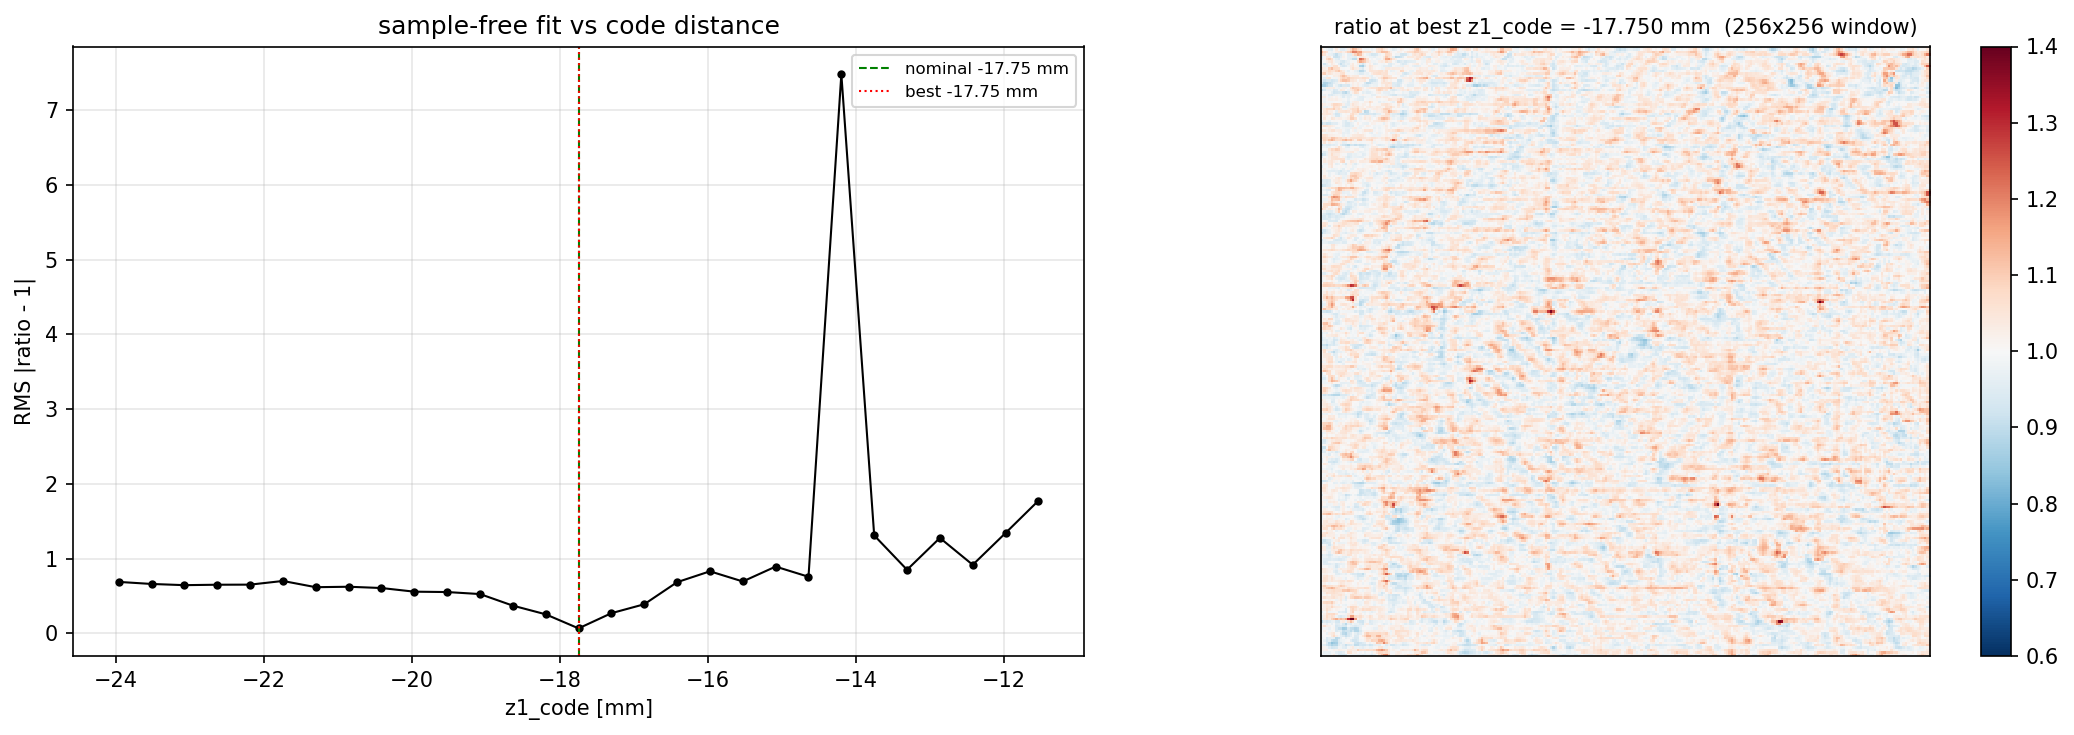

In [6]:
# --- z1_code sweep ------------------------------------------------------------------------------
# z1_code enters the model only through distance_code, i.e. how much the aperture blurs on its way
# from the code plane to the sample plane. If the nominal -17.75 mm is wrong, the modelled code is
# sharper or softer than the measured one and no shift can fix it. Swept at the offset the widget
# above is currently showing, so nudge it to your best alignment first.
ZC_SPAN, ZC_N = 0.35, 29                     # +- fraction of z1_code, points
zc_vals = z1_code * np.linspace(1 - ZC_SPAN, 1 + ZC_SPAN, ZC_N)
zc_rms = np.array([ratio_rms(st['dy'], st['dx'], z)[2] for z in zc_vals])

i_best = int(zc_rms.argmin())
i_nom = int(np.abs(zc_vals - z1_code).argmin())
print(f"offset held at ({st['dy']:+.2f}, {st['dx']:+.2f}) px")
print(f'nominal  z1_code {z1_code * 1e3:8.3f} mm  ->  RMS {zc_rms[i_nom]:.4f}')
print(f'best     z1_code {zc_vals[i_best] * 1e3:8.3f} mm  ->  RMS {zc_rms[i_best]:.4f}'
      f'   ({100 * (zc_rms[i_best] / zc_rms[i_nom] - 1):+.1f}%)')
if i_best in (0, ZC_N - 1):
    print('  WARNING: minimum is on the edge of the swept range -- widen ZC_SPAN')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(zc_vals * 1e3, zc_rms, 'k.-', lw=1)
ax[0].axvline(z1_code * 1e3, color='g', ls='--', lw=1, label=f'nominal {z1_code*1e3:.2f} mm')
ax[0].axvline(zc_vals[i_best] * 1e3, color='r', ls=':', lw=1,
              label=f'best {zc_vals[i_best]*1e3:.2f} mm')
ax[0].set(xlabel='z1_code [mm]', ylabel='RMS |ratio - 1|', title='sample-free fit vs code distance')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

_, r_best, _ = ratio_rms(st['dy'], st['dx'], zc_vals[i_best])
_r0, _c0, _s = _win()
im = ax[1].imshow(r_best[_r0:_r0+_s, _c0:_c0+_s], cmap='RdBu_r', vmin=0.6, vmax=1.4)
ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_title(f'ratio at best z1_code = {zc_vals[i_best]*1e3:.3f} mm  ({_s}x{_s} window)', fontsize=10)
fig.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

set_distance(Dcode, dcode_of(z1_code))       # leave the propagator back at nominal
cp.get_default_memory_pool().free_all_blocks()

## Sanity check: pref0, the propagated probe, the propagated code, and the division

`pref0` has no sample. The probe-only flat is `|D(D_code(prb))|^2` -- probe propagated to the
detector with no aperture and no sample. Dividing one by the other should leave the bare code,
which can then be compared against the code propagated on its own, `|D(D_code(code_window))|^2`.
If the code does not come out clearly, or comes out with the wrong contrast, the probe is suspect.

Worth knowing while reading it: propagation does not commute with multiplication, so
`|D(D_code(prb*code))|^2` is not exactly `|D(D_code(prb))|^2 * |D(D_code(code))|^2`. The
factorisation this comparison rests on is an approximation, so some difference is expected even
with a perfect probe. A large or structured difference is the thing to care about.

pref0            mean 1.0000   std/mean 0.5011
propagated probe mean 1.0525   std/mean 0.4472
pref0 / probe              std/mean 0.2794
propagated code            std/mean 0.2194    contrast ratio 1.2734
difference  RMS 0.1829   ptp 6.3673   correlation 0.7592


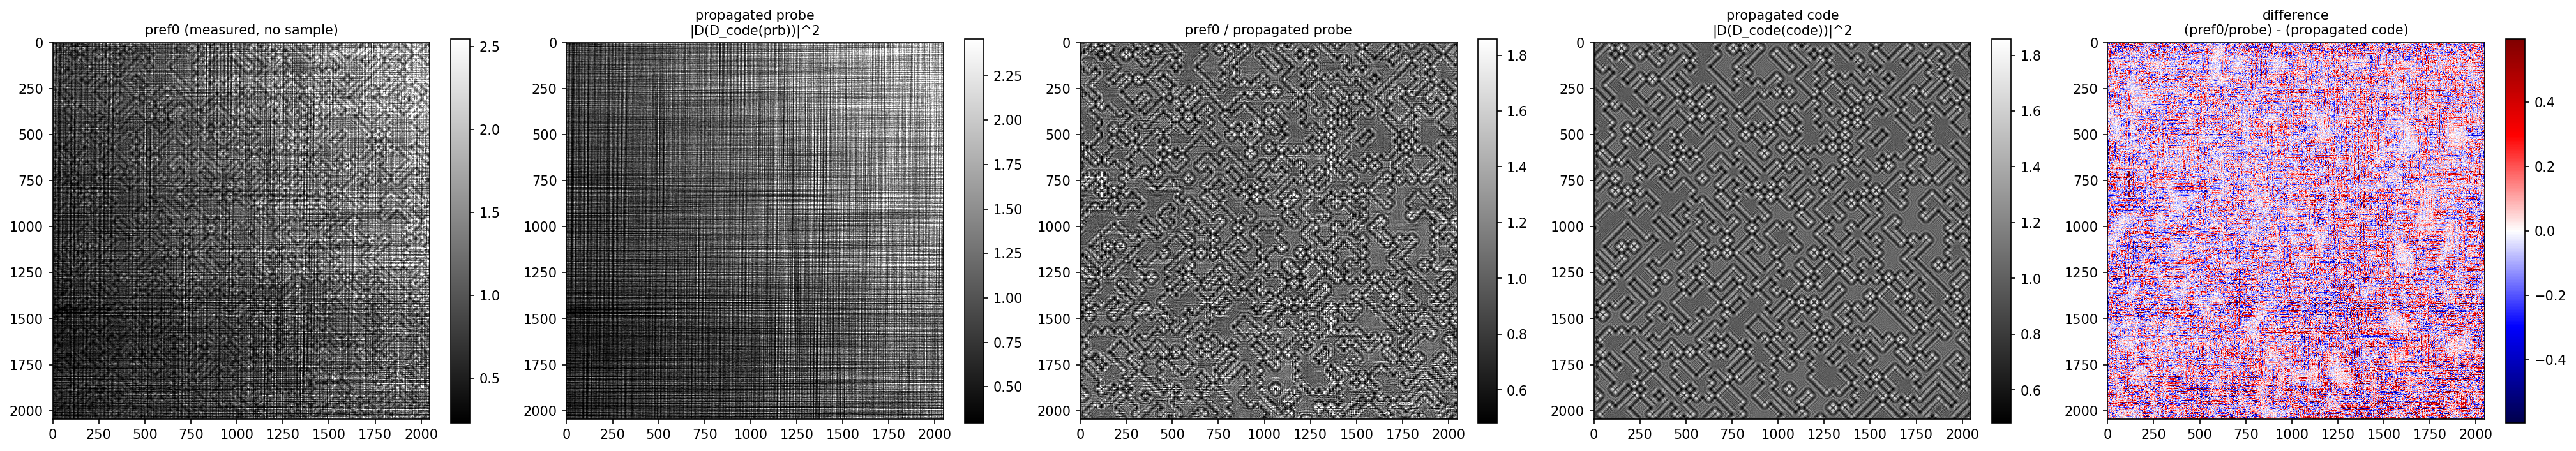

In [7]:
# --- pref0, propagated probe, their division, propagated code, and the difference ---------------
ref_probe = cp.abs(D.D(Dcode.D(prb, 0), 0)) ** 2                 # probe only: no code, no sample
cr, cx = ncode // 2 - sy, ncode // 2 - sx
w_code = code[cr - nz // 2: cr + nz // 2, cx - n // 2: cx + n // 2]
prop_code = cp.asnumpy(cp.abs(D.D(Dcode.D(w_code, 0), 0)) ** 2)  # code only: no probe

rp  = cp.asnumpy(ref_probe)
div = cp.asnumpy(cp.asarray(pref0) / (ref_probe + 1e-6))

c_ = (slice(128, nz - 128), slice(128, n - 128))                 # drop the unreliable rim
a_ = div / np.median(div[c_])                                    # pref0 / probe, normalised
b_ = prop_code / np.median(prop_code[c_])                        # propagated code, normalised
d_ = a_ - b_

print(f'pref0            mean {pref0.mean():.4f}   std/mean {pref0.std()/pref0.mean():.4f}')
print(f'propagated probe mean {rp.mean():.4f}   std/mean {rp.std()/rp.mean():.4f}')
print(f'pref0 / probe              std/mean {a_[c_].std():.4f}')
print(f'propagated code            std/mean {b_[c_].std():.4f}'
      f'    contrast ratio {a_[c_].std()/b_[c_].std():.4f}')
x_ = a_[c_] - a_[c_].mean(); y_ = b_[c_] - b_[c_].mean()
print(f'difference  RMS {np.sqrt((d_[c_]**2).mean()):.4f}   ptp {np.ptp(d_[c_]):.4f}'
      f'   correlation {float((x_*y_).mean()/(np.sqrt((x_*x_).mean())*np.sqrt((y_*y_).mean()))):.4f}')

fig, ax = plt.subplots(1, 5, figsize=(27, 5.8))
for a, img, t in ((ax[0], pref0, 'pref0 (measured, no sample)'),
                  (ax[1], rp,    'propagated probe\n|D(D_code(prb))|^2')):
    lo, hi = np.percentile(img, [1, 99])
    im = a.imshow(img, cmap='gray', vmin=lo, vmax=hi)
    a.set_title(t, fontsize=10); fig.colorbar(im, ax=a, fraction=0.046)
lo, hi = np.percentile(a_, [1, 99])                               # shared scale for the two codes
for a, img, t in ((ax[2], a_, 'pref0 / propagated probe'),
                  (ax[3], b_, 'propagated code\n|D(D_code(code))|^2')):
    im = a.imshow(img, cmap='gray', vmin=lo, vmax=hi)
    a.set_title(t, fontsize=10); fig.colorbar(im, ax=a, fraction=0.046)
v = np.percentile(np.abs(d_), 99)
im = ax[4].imshow(d_, cmap='seismic', vmin=-v, vmax=v)
ax[4].set_title('difference\n(pref0/probe) - (propagated code)', fontsize=10)
fig.colorbar(im, ax=ax[4], fraction=0.046)
plt.tight_layout(); plt.show()
cp.get_default_memory_pool().free_all_blocks()

## NFP self-consistency test -- BLOCKED, needs step0 to save its positions

The test we want is whether `code.npy` and `prb.npy` reproduce the data they were fitted to:

    pdata[k]  ==  | D_nfp( prb * code_window(pos[k]) ) |^2

It cannot be run with what is on disk. `step0.py` refines `pos` during the solve and then
**discards it** -- it saves only `code.npy` and `prb.npy` and logs the mean change
(`mean |dy| 4.410 px, mean |dx| 0.873 px`). `data_nfp.h5`'s `shifts` are step0b's *starting*
estimates, several px from where the solver ended up, and no `.h5` checkpoint was written
(`checkpoints_tiff/` holds only `prb####.npy`), so the refined positions exist nowhere.

Scoring the model at the stale nominal shifts is not the test -- it scores the model at positions
the solver had already rejected. Re-fitting a shift per frame by cross-correlating measurement
against model is not the test either: it fits the quantity under examination, so genuine
code/probe error gets absorbed as a fake position shift, and it is a per-frame estimator where
step0 solved all 324 positions jointly with the code and probe.

**To unblock:** add one line to `step0.py` next to the existing saves,

    np.save(os.path.join(os.path.dirname(args.code_out), 'pos_nfp.npy'),
            cp.asnumpy(cl.vars['pos']))

then re-run step0 and bring the test back using those positions. Cheap, and it also makes the
convergence question directly answerable instead of inferred from a log.